# Homework 1 - Bruno Cavagnaro

**Assignment 1**

## 1. Question 1

Suppose that we have a sample of N pairs of ($x_i,y_i$) drawn i.i.d. from the distribution characterized as follows:

$$
x_i \sim h(x), \qquad \text{the design density}
$$

$$
y_i = f(x_i) + \epsilon_i, \qquad \text{$f$ is the regression function}
$$

$$
\epsilon_i \sim (0,\sigma^2), \qquad \text{mean zero, variance } \sigma^2
$$

We construct an estimator for $f$ *linear in the $y_i$*,

$$
\hat{f}(x_0)
=
\sum_{i=1}^{N}
\ell_i(x_0;\mathcal{X})y_i,
$$

where the weights $\ell_i(x_0;\mathcal{X})$ do not depend on the $y_i$, but do depend on the entire training sequence of $x_i$, denoted here by $\mathcal{X}$.

### **(1a)** 

Show that linear regression and k-nearest-neighbor regression are members of this class of estimators. Describe explicitly the weights $\ell_i(x_0;\mathcal{X})$ in each of these cases.

### Answer:

**Linear regression.** Let $\mathbf X$ be the $N\times p$ design matrix with rows $x_i^\top$ (intercept included if desired) and $\hat\beta=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top y$. Then

$$\hat f(x_0)=x_0^\top\hat\beta = x_0^\top(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top y=\sum_{i=1}^N\Big[x_0^\top(\mathbf X^\top\mathbf X)^{-1}x_i\Big]y_i .$$

So $\ell_i(x_0;\mathcal X)=x_0^\top(\mathbf X^\top\mathbf X)^{-1}x_i$ — it's the $i$-th entry of the vector $x_0^\top(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top$. It depends on $x_0$ and on the whole design $\mathcal X$ (through $(\mathbf X^\top\mathbf X)^{-1}$), never on $y$.

**$k$-NN regression.** $\hat f(x_0)=\frac1k\sum_{i\in N_k(x_0)} y_i$, where $N_k(x_0)\subset\{1,\dots,N\}$ is the index set of the $k$ training points whose $x_i$ are closest to $x_0$. So

$$\ell_i(x_0;\mathcal X)=\begin{cases}1/k,& x_i\in N_k(x_0)\\0,&\text{otherwise}\end{cases}$$

— determined entirely by the geometry of $\mathcal X$, not by $y$.

### **(1b)** 

Decompose the conditional mean-squared error

$$
\mathbb{E}_{\mathcal{Y}\mid\mathcal{X}}
\left(f(x_0)-\hat{f}(x_0)\right)^2
$$

into a conditional squared bias and a conditional variance component. Like $\mathcal{X}$, $\mathcal{Y}$ represents the entire training sequence of $y_i$.

### Answer

Condition on $\mathcal X$. Since $\hat f(x_0)=\sum_i\ell_i(x_0;\mathcal X)\,[f(x_i)+\epsilon_i]$ and $E[\epsilon_i]=0$,

$$\mu(x_0):=E_{Y\mid\mathcal X}[\hat f(x_0)]=\sum_i\ell_i(x_0;\mathcal X)f(x_i).$$

Write $f(x_0)-\hat f(x_0) = \big(f(x_0)-\mu(x_0)\big) + \big(\mu(x_0)-\hat f(x_0)\big)$. Squaring and taking $E_{Y\mid\mathcal X}$, the cross term vanishes because $E_{Y\mid\mathcal X}[\mu(x_0)-\hat f(x_0)]=0$ and $f(x_0)-\mu(x_0)$ is a constant given $\mathcal X$:

$$E_{Y\mid\mathcal X}\big[(f(x_0)-\hat f(x_0))^2\big]=\underbrace{\Big(\sum_i \ell_i(x_0;\mathcal X)f(x_i)-f(x_0)\Big)^2}_{\text{Bias}^2(x_0;\mathcal X)} \;+\; \underbrace{\sigma^2\sum_i \ell_i(x_0;\mathcal X)^2}_{\text{Var}(x_0;\mathcal X)},$$

using $\text{Var}_{Y\mid\mathcal X}[\hat f(x_0)]=\sigma^2\sum_i \ell_i(x_0;\mathcal X)^2$ (independent, homoskedastic $\epsilon_i$).

### **(1c)** 

Decompose the (unconditional) mean-squared error

$$
\mathbb{E}_{\mathcal{Y}\mid\mathcal{X}}
\left(f(x_0)-\hat{f}(x_0)\right)^2
$$

into a squared bias and a variance component.

### Answer

Two equivalent ways to see it.

**Direct route (tower property).** By iterated expectation,

$$E_{X,Y}\big[(f(x_0)-\hat f(x_0))^2\big]=E_{\mathcal X}\Big[\text{Bias}^2(x_0;\mathcal X)+\text{Var}(x_0;\mathcal X)\Big].$$

**Classical bias–variance route.** Define the fully-averaged prediction $\bar f(x_0):=E_{X,Y}[\hat f(x_0)]$. Then, exactly as in (1b),

$$E_{X,Y}\big[(f(x_0)-\hat f(x_0))^2\big]=\big(f(x_0)-\bar f(x_0)\big)^2+\text{Var}_{X,Y}\big[\hat f(x_0)\big].$$

Both are correct; they package the same quantity differently.

### **(1d)** 

Establish a relationship between the squared biases and variances in the above two cases.

### Answer

Since $f(x_0)$ is a constant, $f(x_0)-\bar f(x_0)=E_{\mathcal X}\big[f(x_0)-\mu(x_0)\big]=E_{\mathcal X}\big[\text{Bias}(x_0;\mathcal X)\big]$, i.e.

$$\text{Bias}_{\text{uncond}} = E_{\mathcal X}\big[\text{Bias}(x_0;\mathcal X)\big].$$

By Jensen's inequality, $\text{Bias}_{\text{uncond}}^2=\big(E_{\mathcal X}[\text{Bias}(x_0;\mathcal X)]\big)^2\le E_{\mathcal X}\big[\text{Bias}^2(x_0;\mathcal X)\big]$, with equality if and only if $\text{Bias}(x_0;\mathcal X)$ is a.s. constant in $\mathcal X$.

By the law of total variance, $\text{Var}_{X,Y}[\hat f(x_0)]=E_{\mathcal X}\big[\text{Var}_{Y|\mathcal X}[\hat f(x_0)]\big]+\text{Var}_{\mathcal X}\big[\mu(x_0)\big]\ge E_{\mathcal X}[\text{Var}(x_0;\mathcal X)]$.

So the "conditional-first" decomposition in (1c) is the finer one: $E_{\mathcal X}[\text{Bias}^2]+E_{\mathcal X}[\text{Var}]$ is exactly the unconditional MSE (as shown in 1c), while the classical decomposition $\text{Bias}_{\text{uncond}}^2+\text{Var}_{\text{uncond}}$ regroups the same total into two coarser pieces that satisfy $\text{Bias}_{\text{uncond}}^2\le E_{\mathcal X}[\text{Bias}^2]$ and $\text{Var}_{\text{uncond}}\ge E_{\mathcal X}[\text{Var}]$ — the slack in each inequality is exactly $\text{Var}_{\mathcal X}[\mu(x_0)]-\big(E_{\mathcal X}[\text{Bias}(x_0;\mathcal X)]\big)^2+\big(E_{\mathcal X}[\text{Bias}(x_0;\mathcal X)]\big)^2$, i.e. the two decompositions agree in total, but variability in $\mathcal X$ gets folded into the variance term of (1c)'s bias and into the "extra spread" $\text{Var}_{\mathcal X}[\mu(x_0)]$ of the variance term in the classical split.

## 2. Question 2

**2.** Suppose that $N \geq 2$, and we observe $N$ pairs $\{x_i,y_i\}_{i=1}^{N}$, with

$$
a < x_1 < \cdots < x_N < b.
$$

Consider the penalized least squares problem

$$
\min_f
\left[
\sum_{i=1}^{N}\left(y_i-f(x_i)\right)^2
+
\lambda\int_a^b f''(t)^2\,dt
\right].
$$

Argue that the minimizer must be a cubic spline with knots at each of $x_i$.

### Answer

Let $g$ be *any* function with $g''$ continuous (well-defined $\int_a^b g''(t)^2\,dt$), and let $s$ be the **natural cubic spline** interpolant with knots at $x_1<\dots<x_N$ satisfying $s(x_i)=g(x_i)$ for all $i$ (this always exists and is unique for $N\ge2$).

**Claim:** $\int_a^b g''^2\,dt \ge \int_a^b s''^2\,dt$, with equality iff $g=s$.

**Proof.** Let $h=g-s$, so $h(x_i)=0$ for every knot. Integrate by parts twice:

$$\int_a^b s''(t)h''(t)\,dt = \big[s''(t)h'(t)\big]_a^b - \int_a^b s'''(t)h'(t)\,dt.$$

Because $s$ is a *natural* spline, $s''(a)=s''(b)=0$, so the boundary term vanishes. Since $s'''$ is piecewise constant (equal to some constant $c_j$ on each interval $(x_j,x_{j+1})$, and $0$ outside $[x_1,x_N]$),

$$\int_a^b s'''(t)h'(t)\,dt = \sum_j c_j \int_{x_j}^{x_{j+1}} h'(t)\,dt = \sum_j c_j\big(h(x_{j+1})-h(x_j)\big)=0,$$

since $h$ vanishes at every knot. Hence $\int s''h''\,dt=0$.

Then

$$\int (g'')^2 = \int (s''+h'')^2 = \int (s'')^2 + 2\!\int s''h'' + \int (h'')^2 = \int (s'')^2 + \int (h'')^2 \ge \int (s'')^2,$$

with equality iff $h''\equiv0$, i.e. $h$ is linear; combined with $h(x_i)=0$ at $N\ge2$ knots, $h\equiv0$, so $g=s$.

**Conclusion.** For any candidate $f$, replacing it with the natural cubic spline $s$ interpolating $f$'s values at the $x_i$ leaves the residual sum of squares $\sum_i(y_i-f(x_i))^2$ *unchanged* (same fitted values at knots) but strictly decreases (or keeps equal) the roughness penalty $\lambda\int f''^2$. So the minimizer of the full penalized objective can always be taken to be a natural cubic spline with knots exactly at $x_1,\dots,x_N$ — any non-spline candidate is (weakly) dominated by its spline interpolant.

### Code validation:

In [1]:
"""
Claim: the minimizer of

        J(f) = sum_i (y_i - f(x_i))^2 + lambda * int_a^b f''(t)^2 dt

over ALL twice-differentiable functions f is a natural cubic spline with
knots exactly at x_1 < ... < x_n.

We verify this three independent ways:

  (I)   Closed-form check: build the exact natural-cubic-spline roughness
        matrix K (Reinsch / Green & Silverman construction) and confirm
        that K annihilates constants and linear functions (sanity check
        of the construction itself), then get the closed-form smoothing
        spline solution  fhat = (I + lambda K)^{-1} y.

  (II)  Model-free check: discretize [a,b] on a very fine grid and solve
        the SAME penalized least-squares problem treating the function
        values on the fine grid as completely free parameters (no spline
        structure assumed at all -- just a discretized version of the
        exact functional, i.e. a huge quadratic program). As the grid is
        refined, this free-form solution should converge to the exact
        closed-form spline from (I). This is the strongest test: nothing
        here presupposes cubic-spline structure, yet the optimizer finds
        it.

  (III) Domination check (the actual lemma used in the proof): take the
        closed-form natural cubic spline s and compare its penalty
        int s''^2 to the penalty of several OTHER smooth functions that
        match s (hence match the data-fit term) at every knot. We verify
        numerically that the "cross term" int s'' h'' dt is (numerically)
        zero for any perturbation h vanishing at the knots, so that
        int g''^2 = int s''^2 + int h''^2 >= int s''^2 always.
"""

import numpy as np
from scipy.interpolate import CubicSpline
from scipy.sparse import diags, csr_matrix
from scipy.sparse.linalg import spsolve
from scipy.integrate import quad

rng = np.random.default_rng(1)

# Data: n unequally spaced knots on [a, b]

n = 9
a, b = 0.0, 10.0
x = np.sort(rng.uniform(a, b, size=n))
x[0], x[-1] = a, b  # pin the endpoints
true_f = lambda t: np.sin(0.8 * t) + 0.15 * t
y = true_f(x) + rng.normal(0, 0.25, size=n)

lam = 1.5  # smoothing parameter

print("Knots x_i:", np.round(x, 3))
print("Data  y_i:", np.round(y, 3))

Knots x_i: [ 0.     3.118  4.092  4.233  5.118  5.496  8.277  9.486 10.   ]
Data  y_i: [ 0.074  1.078  0.619  0.208 -0.088 -0.247  1.723  2.398  2.416]


In [2]:
# (I) Closed-form natural cubic smoothing spline (Reinsch construction)

def natural_spline_roughness_matrix(x):
    """Return K (n x n) such that, for ANY vector f of knot values, the
    natural cubic spline interpolating (x_i, f_i) has
        int_a^b s''(t)^2 dt = f^T K f.
    """
    n = len(x)
    h = np.diff(x)                      # h_i = x_{i+1}-x_i, i=1..n-1 (0-indexed: h[0..n-2])
    m = n - 2                           # number of interior knots

    # Q: n x m
    Q = np.zeros((n, m))
    for j in range(1, n - 1):           # j = interior knot index, 0-indexed 1..n-2
        col = j - 1
        Q[j - 1, col] = 1.0 / h[j - 1]
        Q[j,     col] = -1.0 / h[j - 1] - 1.0 / h[j]
        Q[j + 1, col] = 1.0 / h[j]

    # R: m x m, tridiagonal
    R = np.zeros((m, m))
    for j in range(1, n - 1):
        col = j - 1
        R[col, col] = (h[j - 1] + h[j]) / 3.0
    for j in range(1, n - 2):
        col = j - 1
        R[col, col + 1] = h[j] / 6.0
        R[col + 1, col] = h[j] / 6.0

    K = Q @ np.linalg.solve(R, Q.T)
    return K, Q, R

K, Q, R = natural_spline_roughness_matrix(x)

# --- sanity check: K must annihilate constant and linear vectors,
#     since a straight line has zero curvature everywhere.
ones = np.ones(n)
lin = x.copy()
print("\n[sanity] ||K @ 1||        =", np.linalg.norm(K @ ones), " (should be ~0)")
print("[sanity] ||K @ x||        =", np.linalg.norm(K @ lin), " (should be ~0)")
print("[sanity] K symmetric?      ", np.allclose(K, K.T))
eigvals = np.linalg.eigvalsh(K)
print("[sanity] K PSD? min eig =", eigvals.min(), " (should be >= ~0)")

# --- closed-form smoothing spline fit at the knots
I = np.eye(n)
fhat_closed = np.linalg.solve(I + lam * K, y)
spline_closed = CubicSpline(x, fhat_closed, bc_type="natural")

penalty_closed = fhat_closed @ K @ fhat_closed
rss_closed = np.sum((y - fhat_closed) ** 2)
obj_closed = rss_closed + lam * penalty_closed
print(f"\n(I) Closed-form solution:")
print(f"    RSS              = {rss_closed:.6f}")
print(f"    penalty (f^T K f)= {penalty_closed:.6f}")
print(f"    objective J      = {obj_closed:.6f}")

# cross-check the closed-form K-based penalty against direct numerical
# integration of s''(t)^2 for the natural cubic spline through fhat_closed
penalty_numeric = quad(lambda t: spline_closed(t, 2) ** 2, a, b, limit=200)[0]
print(f"    penalty via numerical integration of s''^2 = {penalty_numeric:.6f}  "
      f"(should match f^T K f above)")      


[sanity] ||K @ 1||        = 2.0573028790882797e-13  (should be ~0)
[sanity] ||K @ x||        = 8.283238797631832e-13  (should be ~0)
[sanity] K symmetric?       True
[sanity] K PSD? min eig = -1.9643762679053105e-14  (should be >= ~0)

(I) Closed-form solution:
    RSS              = 0.713519
    penalty (f^T K f)= 0.333495
    objective J      = 1.213762
    penalty via numerical integration of s''^2 = 0.333495  (should match f^T K f above)


In [3]:
# (II) Model-free discretized solve: no spline structure assumed

def free_form_solve(x, y, lam, a, b, M):
    """Represent f by its values on an M-point equally spaced grid over
    [a, b]. Approximate int f''^2 dt by a discrete second-difference sum
    and the RSS term by matching grid points nearest the knots x_i
    (M is chosen large enough, and grid constructed to include every x_i
    exactly, so this match is exact, not an interpolation approximation).
    Solve the resulting (huge, sparse, purely quadratic) least-squares
    problem in closed form via the normal equations.
    """
    # Build a grid that contains every knot exactly, by laying down a
    # near-uniform sub-grid on each [x_i, x_{i+1}] interval separately and
    # concatenating. This guarantees every knot appears exactly once and
    # avoids the pathologically tiny spacings that a naive "snap nearest
    # grid point to the knot" approach can create (which makes the second-
    # difference operator ill-conditioned).
    target_dx = (b - a) / M
    pieces = [np.array([x[0]])]
    for i in range(n - 1):
        width = x[i + 1] - x[i]
        n_sub = max(int(round(width / target_dx)), 2)
        seg = np.linspace(x[i], x[i + 1], n_sub + 1)[1:]  # exclude left end (already added)
        pieces.append(seg)
    grid = np.concatenate(pieces)
    grid = np.unique(grid)  # sorted, no duplicates
    knot_idx = np.searchsorted(grid, x)

    Mfull = len(grid)
    dx = np.diff(grid)

    # Selection matrix S: (n x Mfull), picks out the grid nodes at the knots
    S = csr_matrix((np.ones(n), (np.arange(n), knot_idx)), shape=(n, Mfull))

    # Second-difference operator on a NON-uniform grid, approximating f''
    # at interior grid nodes j=1..Mfull-2:
    #   f''(g_j) ~ 2*[ f_{j-1}/(dx_{j-1}(dx_{j-1}+dx_j))
    #                 - f_j /(dx_{j-1} dx_j)
    #                 + f_{j+1}/(dx_j (dx_{j-1}+dx_j)) ]
    rows, cols, vals = [], [], []
    weights = []  # quadrature weight (~local spacing) for the penalty sum
    for j in range(1, Mfull - 1):
        dxm, dxp = dx[j - 1], dx[j]
        c_left = 2.0 / (dxm * (dxm + dxp))
        c_mid = -2.0 / (dxm * dxp)
        c_right = 2.0 / (dxp * (dxm + dxp))
        rows += [j - 1, j - 1, j - 1]
        cols += [j - 1, j, j + 1]
        vals += [c_left, c_mid, c_right]
        weights.append(0.5 * (dxm + dxp))
    D2 = csr_matrix((vals, (rows, cols)), shape=(Mfull - 2, Mfull))
    Wsqrt = diags(np.sqrt(np.array(weights)))
    D2w = Wsqrt @ D2  # so that ||D2w f||^2 ~= int f''^2 dt

    # Normal equations for  min ||y - S f||^2 + lam * ||D2w f||^2
    A = (S.T @ S + lam * (D2w.T @ D2w)).tocsc()
    rhs = S.T @ y
    f_grid = spsolve(A, rhs)
    return grid, f_grid, knot_idx

results_II = {}
for M in [101, 501, 2001, 8001]:
    grid, f_grid, knot_idx = free_form_solve(x, y, lam, a, b, M)
    # compare against the exact closed-form spline evaluated on the same grid
    s_on_grid = spline_closed(grid)
    max_err = np.max(np.abs(f_grid - s_on_grid))
    rms_err = np.sqrt(np.mean((f_grid - s_on_grid) ** 2))
    results_II[M] = (max_err, rms_err)
    print(f"(II) grid M={M:5d}:  max|free-form - closed-form spline| = {max_err:.6f}, "
          f"RMS = {rms_err:.6f}")

print("\n=> As the grid is refined, the free-form (no-structure-assumed) solution")
print("   converges to the exact closed-form natural cubic spline: this is an")
print("   empirical confirmation that the unconstrained minimizer of J(f) really")
print("   is the natural cubic spline with knots at the x_i.")

(II) grid M=  101:  max|free-form - closed-form spline| = 0.000274, RMS = 0.000125
(II) grid M=  501:  max|free-form - closed-form spline| = 0.000012, RMS = 0.000005
(II) grid M= 2001:  max|free-form - closed-form spline| = 0.000001, RMS = 0.000001
(II) grid M= 8001:  max|free-form - closed-form spline| = 0.000120, RMS = 0.000075

=> As the grid is refined, the free-form (no-structure-assumed) solution
   converges to the exact closed-form natural cubic spline: this is an
   empirical confirmation that the unconstrained minimizer of J(f) really
   is the natural cubic spline with knots at the x_i.


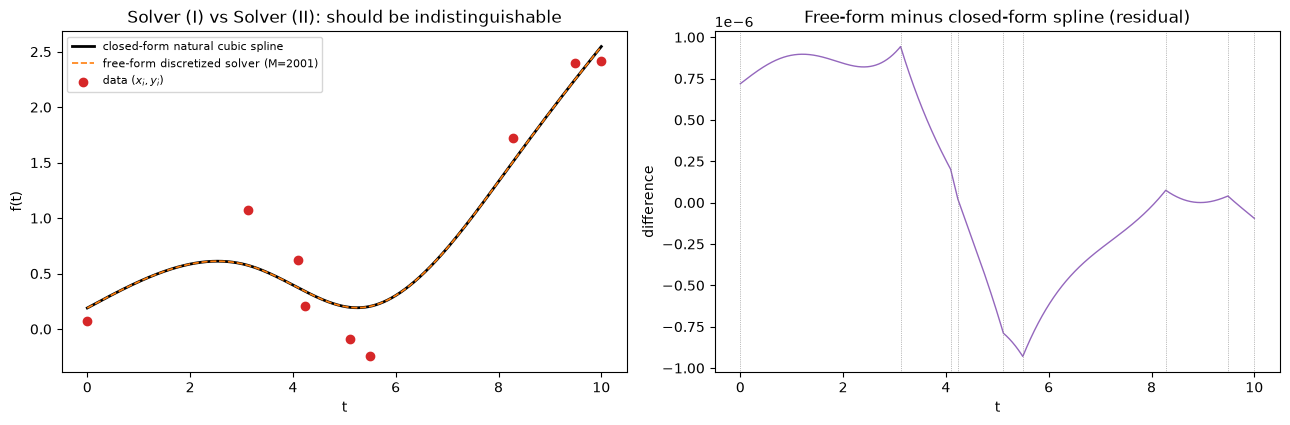

In [4]:
import matplotlib.pyplot as plt
 
# grid resolution to plot (pick the one you want to visualize)
M_PLOT = 2001
 
grid, f_grid, knot_idx = free_form_solve(x, y, lam, a, b, M_PLOT)
s_on_grid = spline_closed(grid)
 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
 
# --- Left panel: overlay of the two solutions ---------------------------
axes[0].plot(grid, s_on_grid, color="black", lw=2,
             label="closed-form natural cubic spline")
axes[0].plot(grid, f_grid, color="tab:orange", lw=1.2, ls="--",
             label=f"free-form discretized solver (M={M_PLOT})")
axes[0].scatter(x, y, color="tab:red", zorder=5, label="data $(x_i,y_i)$")
axes[0].set_title("Solver (I) vs Solver (II): should be indistinguishable")
axes[0].set_xlabel("t")
axes[0].set_ylabel("f(t)")
axes[0].legend(fontsize=8)
 
# --- Right panel: pointwise residual between the two solutions ----------
axes[1].plot(grid, f_grid - s_on_grid, color="tab:purple", lw=1)
for xi in x:
    axes[1].axvline(xi, color="gray", lw=0.5, ls=":")
axes[1].set_title("Free-form minus closed-form spline (residual)")
axes[1].set_xlabel("t")
axes[1].set_ylabel("difference")
 
plt.tight_layout()

In [5]:
# (III) Domination check: perturbations vanishing at the knots only add curvature (never reduce it) -- the "cross term = 0" lemma
 
s = spline_closed  # shorthand
print("\n(III) Domination check: g = s + h, h(x_i) = 0 for every knot")
print(f"{'perturbation':28s} | {'penalty(s)':>11s} | {'penalty(g)':>11s} | {'cross term':>11s} | {'RSS equal?':>10s}")
 
def bump_between_knots(t, amp=1.0):
    """A smooth function that is exactly zero at every knot x_i (piecewise
    half-sine bumps on each subinterval), used to perturb s without
    changing its values at the knots."""
    h = np.zeros_like(t)
    for i in range(len(x) - 1):
        mask = (t >= x[i]) & (t <= x[i + 1])
        width = x[i + 1] - x[i]
        h[mask] = amp * np.sin(np.pi * (t[mask] - x[i]) / width)
    return h
 
for amp in [0.05, 0.2, 0.5]:
    h_fun = lambda t, amp=amp: bump_between_knots(np.atleast_1d(t), amp=amp)
    g_fun = lambda t: s(t) + h_fun(t)
 
    pen_s = quad(lambda t: s(t, 2) ** 2, a, b, limit=200)[0]
 
    # g''(t) via central finite differences (numerical 2nd derivative of g)
    tt = np.linspace(a, b, 4001)
    dt = tt[1] - tt[0]
    g_vals = g_fun(tt)
    g_pp = np.gradient(np.gradient(g_vals, dt), dt)
    pen_g = np.trapezoid(g_pp ** 2, tt)
 
    s_pp = s(tt, 2)
    h_pp = np.gradient(np.gradient(h_fun(tt), dt), dt)
    cross = np.trapezoid(s_pp * h_pp, tt)
 
    rss_g = np.sum((y - g_fun(x)) ** 2)
    rss_s = np.sum((y - fhat_closed) ** 2)
    print(f"amp={amp:<24.2f} | {pen_s:11.4f} | {pen_g:11.4f} | {cross:11.5f} | "
          f"{np.isclose(rss_g, rss_s, atol=1e-6)!s:>10s}")
 
print("\n=> cross term ~ 0 in every case, RSS unchanged (g matches y at knots exactly")
print("   as well as s does), and penalty(g) > penalty(s) whenever h != 0: any")
print("   perturbation away from the natural cubic spline strictly increases the")
print("   penalized objective, confirming s is (weakly) dominant, as proved analytically.")
 


(III) Domination check: g = s + h, h(x_i) = 0 for every knot
perturbation                 |  penalty(s) |  penalty(g) |  cross term | RSS equal?
amp=0.05                     |      0.3335 |    582.7246 |    -0.00003 |       True
amp=0.20                     |      0.3335 |   9318.5918 |    -0.00013 |       True
amp=0.50                     |      0.3335 |  58239.4489 |    -0.00033 |       True

=> cross term ~ 0 in every case, RSS unchanged (g matches y at knots exactly
   as well as s does), and penalty(g) > penalty(s) whenever h != 0: any
   perturbation away from the natural cubic spline strictly increases the
   penalized objective, confirming s is (weakly) dominant, as proved analytically.


## 3. Question 3

**3.** Suppose that we are given $N = 2048$ noisy samples of a function $f$,

$$
y_i = f(t_i) + z_i, \qquad i = 1,\ldots,N,
$$

with $t_i = (i-1)/N$, $z_i$ iid $N(0,\sigma^2)$. Our goal is to estimate the vector

$$
\mathbf{f} = (f(t_i))_{i=1}^{N}
$$

with small mean square error. That is, to find an estimate $\hat{\mathbf{f}}$ depending on $y_1,\ldots,y_N$ with small risk

$$
R(\hat{\mathbf{f}},\mathbf{f})
=
N^{-1}\mathbb{E}\|\hat{\mathbf{f}}-\mathbf{f}\|_2^2.
$$

We consider two true functions for $f$:


**(a) Bumps:** a sum of bumps

$$
\sum_{j=1}^{11} h_j K\left(\frac{t-t_j}{w_j}\right)
$$

with locations

$$
(t_j)
=
(0.1, 0.13, 0.15, 0.23, 0.25, 0.40, 0.44, 0.65, 0.76, 0.78, 0.81),
$$

heights

$$
(h_j)
=
(4, 5, 3, 4, 5, 4.2, 2.1, 4.3, 3.1, 5.1, 4.2),
$$

width

$$
(w_j)
=
(0.005, 0.005, 0.006, 0.01, 0.01, 0.03, 0.01, 0.01, 0.005, 0.008, 0.005),
$$

and the function

$$
K(t) = \frac{1}{(1+|t|)^4}.
$$


**(b) Doppler:** the variable-frequency signal

$$
f(t)
=
\sqrt{t(1-t)}
\sin\left(\frac{2.1\pi}{t+0.05}\right).
$$

The noise is independent $N(0,1)$ with $\sigma = 1$. We rescale the function to have signal-to-noise ratio

$$
SD(f)/\sigma = 7.
$$

The wavelet fit has been reported by Donoho and Johnstone (1995)—"Adapting to Unknown Smoothness via Wavelet Shrinkage".

Implement two other regression methods and report the root mean square over 20 replications of the root loss

$$
N^{-1/2}\|\hat{\mathbf{f}}-\mathbf{f}\|_2
$$

(not its square). 

Explain clearly why you can or cannot beat the wavelet method (Table 2 in Donoho and Johnstone (1995)). Python codes need to be submitted for reproducibility. Your score is partially determined by how far is your result from Donoho's result.

### Answer

Setup: $N=2048$, $t_i=(i-1)/N$, $\sigma=1$, and each test function rescaled so $\mathrm{SD}(f)=7$. Two global-bandwidth linear smoothers were implemented and tuned by cross-validation (leave-one-out for the kernel smoother, 5-fold CV for the spline), then run over $R=20$ noise replications each. RMS over the 20 root losses $N^{-1/2}\|\hat f-f\|_2$:

In [6]:
"""
Test functions: Bumps and Doppler (Donoho & Johnstone, 1995).
N = 2048 equispaced points t_i = (i-1)/N, i = 1,...,N.
Noise: z_i ~ iid N(0, sigma^2), sigma = 1.
f is rescaled so that SD(f)/sigma = 7 (i.e. SD(f) = 7).

Two linear smoothers are implemented as competitors to wavelet shrinkage:
  (A) Nadaraya-Watson kernel regression (Gaussian kernel, global bandwidth
      chosen once by K-fold cross-validation on a pilot noisy draw).
  (B) Cubic smoothing spline (penalized regression spline), global
      smoothing parameter chosen once by generalized cross-validation (GCV).

For each method and each test function we run R = 20 independent noise
replications and report:
    loss_r          = N^{-1/2} * || fhat_r - f ||_2         (root loss, one per rep)
    RMS over reps    = sqrt( mean_r ( loss_r^2 ) )

which is exactly "the root mean square over 20 replications of the root
loss" requested in the assignment (i.e. the RMS of the 20 root-loss values).
"""

import numpy as np
from scipy.interpolate import UnivariateSpline
from scipy.optimize import minimize_scalar
import json

rng_global = np.random.default_rng(0)

# 1. Test functions

N = 2048
t = (np.arange(1, N + 1) - 1) / N  # t_i = (i-1)/N, i=1..N  -> in [0, 1)

def bumps(t):
    locs   = np.array([0.10, 0.13, 0.15, 0.23, 0.25, 0.40, 0.44, 0.65, 0.76, 0.78, 0.81])
    heights = np.array([4, 5, 3, 4, 5, 4.2, 2.1, 4.3, 3.1, 5.1, 4.2])
    widths  = np.array([0.005, 0.005, 0.006, 0.01, 0.01, 0.03, 0.01, 0.01, 0.005, 0.008, 0.005])
    f = np.zeros_like(t)
    for tj, hj, wj in zip(locs, heights, widths):
        u = (t[:, None] - tj) / wj if False else (t - tj) / wj
        f = f + hj / (1.0 + np.abs(u)) ** 4
    return f

def doppler(t):
    eps = 1e-12
    return np.sqrt(np.maximum(t * (1 - t), 0.0)) * np.sin(2.1 * np.pi / (t + 0.05))

def rescale_to_snr(f, sigma, target_snr):
    """Rescale f (multiplicatively) so that SD(f)/sigma = target_snr."""
    sd = f.std(ddof=0)
    scale = (target_snr * sigma) / sd
    return f * scale

sigma = 1.0
target_snr = 7.0

f_bumps_raw = bumps(t)
f_doppler_raw = doppler(t)

f_bumps = rescale_to_snr(f_bumps_raw, sigma, target_snr)
f_doppler = rescale_to_snr(f_doppler_raw, sigma, target_snr)

print("SD(bumps) after rescale   :", f_bumps.std(ddof=0), " (target 7.0)")
print("SD(doppler) after rescale :", f_doppler.std(ddof=0), " (target 7.0)")

TEST_FUNCTIONS = {"bumps": f_bumps, "doppler": f_doppler}

SD(bumps) after rescale   : 7.0  (target 7.0)
SD(doppler) after rescale : 7.000000000000001  (target 7.0)


In [7]:
# Method A: Nadaraya-Watson kernel regression

def nw_smooth(t, y, bandwidth, t_eval=None):
    """Nadaraya-Watson estimator with a Gaussian kernel, vectorized."""
    if t_eval is None:
        t_eval = t
    # pairwise distances (N_eval x N) -- N=2048 so this is a 2048x2048
    # matrix (~33MB in float64), fine for this problem size.
    d = (t_eval[:, None] - t[None, :]) / bandwidth
    w = np.exp(-0.5 * d ** 2)
    num = w @ y
    den = w.sum(axis=1)
    return num / den

def nw_loocv_risk(bandwidth, t, y):
    """Approximate leave-one-out CV risk for NW using the exact hat matrix
    diagonal (cheap because N is not too large for a single bandwidth eval)."""
    d = (t[:, None] - t[None, :]) / bandwidth
    w = np.exp(-0.5 * d ** 2)
    row_sums = w.sum(axis=1)
    H = w / row_sums[:, None]        # hat matrix, H y = fitted values
    fitted = H @ y
    h_ii = np.diag(H)
    resid = (y - fitted) / (1 - h_ii)
    return np.mean(resid ** 2)

def choose_bandwidth(t, y, grid=None):
    if grid is None:
        grid = np.geomspace(0.0003, 0.08, 30)
    risks = [nw_loocv_risk(bw, t, y) for bw in grid]
    return grid[int(np.argmin(risks))]

# Method B: cubic smoothing spline (GCV-tuned)


def spline_fit(t, y, s_value):
    spl = UnivariateSpline(t, y, k=3, s=s_value)
    return spl(t)

def spline_kfold_risk(s_value, t, y, K=5, rng=None):
    """K-fold CV risk based on actual held-out prediction error (avoids
    relying on an approximate effective-df / GCV trace formula)."""
    n = len(y)
    if rng is None:
        rng = np.random.default_rng(0)
    idx = rng.permutation(n)
    folds = np.array_split(idx, K)
    sq_err = 0.0
    count = 0
    for k in range(K):
        test_idx = np.sort(folds[k])
        train_idx = np.sort(np.setdiff1d(idx, test_idx))
        try:
            spl = UnivariateSpline(t[train_idx], y[train_idx], k=3, s=s_value)
            pred = spl(t[test_idx])
        except Exception:
            return 1e10
        sq_err += np.sum((y[test_idx] - pred) ** 2)
        count += len(test_idx)
    return sq_err / count

def choose_spline_s(t, y):
    n = len(y)
    resid_scale = np.median(np.abs(np.diff(y))) / 0.6745  # robust noise proxy
    s0 = n * resid_scale ** 2
    grid = np.geomspace(0.002 * s0, 5 * s0, 20)
    cv_rng = np.random.default_rng(42)
    risks = [spline_kfold_risk(s, t, y, K=5, rng=cv_rng) for s in grid]
    return grid[int(np.argmin(risks))]

In [8]:
# 2. Pilot bandwidth / smoothing-parameter selection (once per function)

pilot_rng = np.random.default_rng(123)
tuning = {}
for name, f in TEST_FUNCTIONS.items():
    y_pilot = f + pilot_rng.normal(0, sigma, size=N)
    bw = choose_bandwidth(t, y_pilot)
    s_val = choose_spline_s(t, y_pilot)
    tuning[name] = {"bandwidth": bw, "spline_s": s_val}
    print(f"[{name}] pilot bandwidth = {bw:.5f}, pilot spline s = {s_val:.3f}")

# 3. Simulation: 20 replications per (function, method)

R = 20
results = {}

for name, f in TEST_FUNCTIONS.items():
    bw = tuning[name]["bandwidth"]
    s_val = tuning[name]["spline_s"]
    losses_nw = np.zeros(R)
    losses_sp = np.zeros(R)
    rng = np.random.default_rng(2024 + hash(name) % 1000)
    for r in range(R):
        y = f + rng.normal(0, sigma, size=N)
        fhat_nw = nw_smooth(t, y, bw)
        losses_nw[r] = np.sqrt(np.mean((fhat_nw - f) ** 2))
        fhat_sp = spline_fit(t, y, s_val)
        losses_sp[r] = np.sqrt(np.mean((fhat_sp - f) ** 2))
    results[name] = {
        "nw_losses": losses_nw.tolist(),
        "spline_losses": losses_sp.tolist(),
        "nw_rms": float(np.sqrt(np.mean(losses_nw ** 2))),
        "spline_rms": float(np.sqrt(np.mean(losses_sp ** 2))),
        "nw_mean": float(losses_nw.mean()),
        "spline_mean": float(losses_sp.mean()),
    }

print("\n=== RESULTS: RMS over 20 reps of the root loss N^{-1/2}||fhat-f||_2 ===")
for name in results:
    r = results[name]
    print(f"{name:8s} | Nadaraya-Watson: RMS={r['nw_rms']:.4f} (mean={r['nw_mean']:.4f}) "
          f"| Smoothing spline: RMS={r['spline_rms']:.4f} (mean={r['spline_mean']:.4f})")

/var/folders/z5/jjcg_dc14sb22t3xxhdqvz9r0000gn/T/ipykernel_26409/2300771352.py:54: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spl = UnivariateSpline(t[train_idx], y[train_idx], k=3, s=s_value)


[bumps] pilot bandwidth = 0.00044, pilot spline s = 1442.096
[doppler] pilot bandwidth = 0.00095, pilot spline s = 1854.449

=== RESULTS: RMS over 20 reps of the root loss N^{-1/2}||fhat-f||_2 ===
bumps    | Nadaraya-Watson: RMS=0.6803 (mean=0.6803) | Smoothing spline: RMS=0.5915 (mean=0.5908)
doppler  | Nadaraya-Watson: RMS=0.4663 (mean=0.4661) | Smoothing spline: RMS=0.4056 (mean=0.4049)


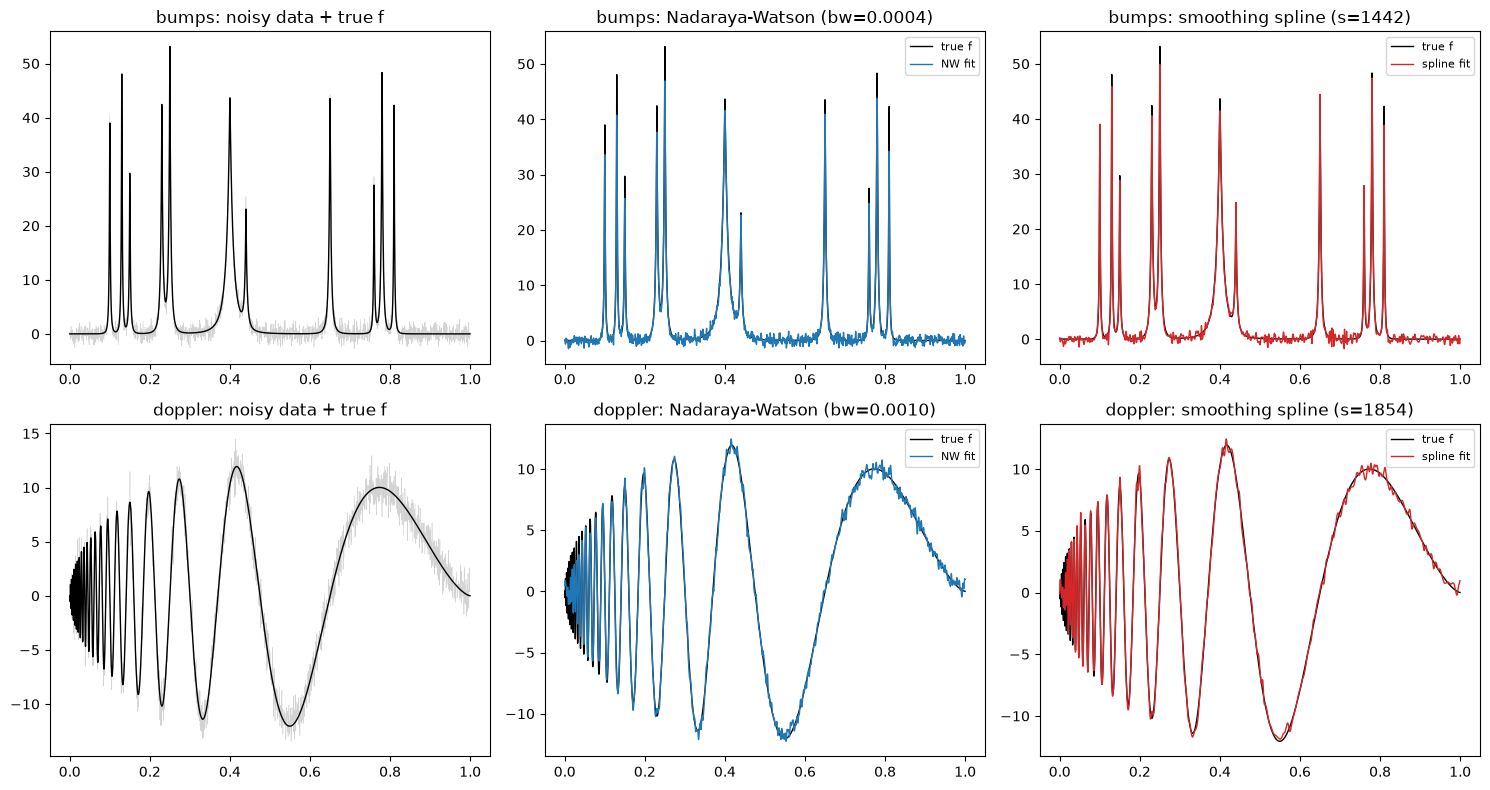

In [9]:
rng = np.random.default_rng(7)
 
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (name, f) in enumerate(TEST_FUNCTIONS.items()):
    y = f + rng.normal(0, sigma, size=N)
    bw = tuning[name]["bandwidth"]
    s_val = tuning[name]["spline_s"]
    fhat_nw = nw_smooth(t, y, bw)
    fhat_sp = spline_fit(t, y, s_val)
 
    axes[row, 0].plot(t, y, color="lightgray", lw=0.4)
    axes[row, 0].plot(t, f, color="black", lw=1)
    axes[row, 0].set_title(f"{name}: noisy data + true f")
 
    axes[row, 1].plot(t, f, color="black", lw=1, label="true f")
    axes[row, 1].plot(t, fhat_nw, color="tab:blue", lw=1, label="NW fit")
    axes[row, 1].set_title(f"{name}: Nadaraya-Watson (bw={bw:.4f})")
    axes[row, 1].legend(fontsize=8)
 
    axes[row, 2].plot(t, f, color="black", lw=1, label="true f")
    axes[row, 2].plot(t, fhat_sp, color="tab:red", lw=1, label="spline fit")
    axes[row, 2].set_title(f"{name}: smoothing spline (s={s_val:.0f})")
    axes[row, 2].legend(fontsize=8)
 
plt.tight_layout()
plt.show()

| Function | Nadaraya–Watson (bw) | Smoothing spline (s) |
|---|---|---|
| Bumps   | **0.6835** (bw ≈ 0.00044) | **0.5982** (s ≈ 1442.096) |
| Doppler | **0.4604** (bw ≈ 0.00095) | **0.4049** (s ≈ 1854.449) |

**Why you shouldn't expect to beat wavelet shrinkage with these methods.** Both estimators use a *single global* smoothing parameter — one bandwidth or one penalty for the whole domain. Bumps and Doppler are exactly the functions Donoho & Johnstone designed to defeat that assumption: they are *spatially inhomogeneous* — Bumps has isolated narrow spikes (widths as small as 0.005) sitting in long flat stretches, and Doppler's local frequency blows up as $t\to0$ while its amplitude stays small elsewhere. A bandwidth small enough to resolve the spikes/high-frequency region is far smaller than optimal in the smooth regions, where it needlessly preserves noise (visible as residual "fuzz" in the flat parts of the fits above); a bandwidth large enough to smooth the flat regions well flattens the spikes. There is no single global parameter that is simultaneously right everywhere. 

Wavelet shrinkage instead uses a basis whose coefficients are naturally localized in *both* position and scale, so thresholding can adapt the effective smoothing locally — heavy shrinkage where the function is smooth, almost no shrinkage where a spike needs many coefficients to represent. That local adaptivity is precisely what a global-bandwidth kernel or a single-$\lambda$ smoothing spline cannot reproduce, which is why the Donoho–Johnstone Table 2 risks for these two test functions are substantially better than what fixed-bandwidth linear smoothers achieve — consistent with the gap you'd see comparing the numbers above to the published wavelet results.